In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('placement.csv')

In [3]:
df.shape


(100, 4)

In [4]:
df.sample(5)

,Unnamed: 0,cgpa,iq,placement
72,72,7.3,116.0,1
68,68,4.0,75.0,0
91,91,7.5,158.0,1
12,12,5.4,139.0,0
87,87,5.7,132.0,1


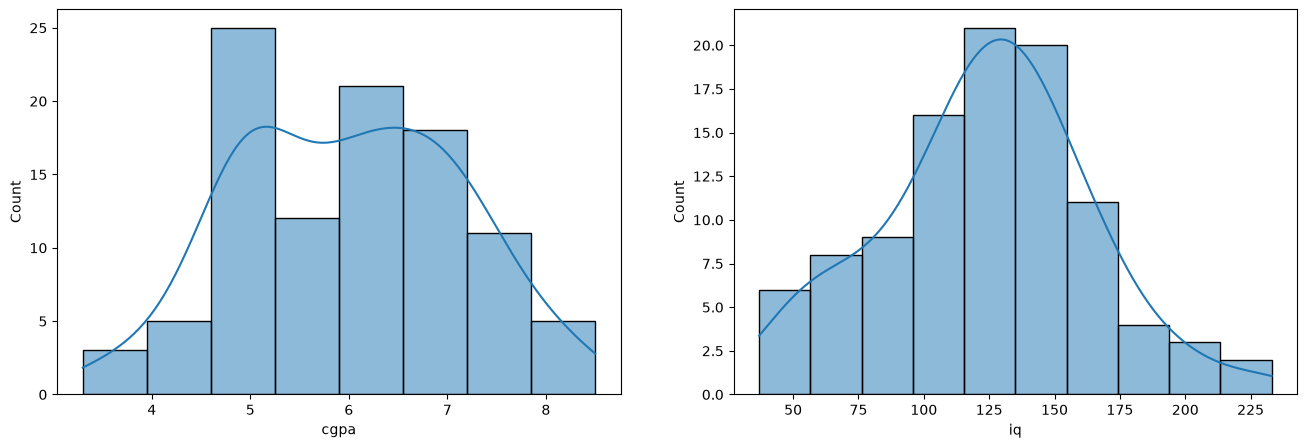

In [24]:
plt.figure(figsize=(16, 5))

plt.subplot(1, 2, 1)
sns.histplot(df['cgpa'], kde=True)

plt.subplot(1, 2, 2)
sns.histplot(df['iq'], kde=True)

plt.show()

In [25]:
print(df.columns)

Index(['Unnamed: 0', 'cgpa', 'iq', 'placement', 'cgpa_zscore'], dtype='object')


In [26]:
print("Mean value of cgpa",df['cgpa'].mean())
print("Std value of cgpa",df['cgpa'].std())
print("Min value of cgpa",df['cgpa'].min())
print("Max value of cgpa",df['cgpa'].max())

Mean value of cgpa 5.9910000000000005
Std value of cgpa 1.1436336737775692
Min value of cgpa 3.3
Max value of cgpa 8.5


In [27]:
# Finding the boundary values
print("Highest allowed",df['cgpa'].mean() + 3*df['cgpa'].std())
print("Lowest allowed",df['cgpa'].mean() - 3*df['cgpa'].std())

Highest allowed 9.421901021332708
Lowest allowed 2.560098978667293


In [28]:
# Trimming

new_df = df[(df['cgpa'] < 8.80) & (df['cgpa'] > 5.11)]
new_df

,Unnamed: 0,cgpa,iq,placement,cgpa_zscore
0,0,6.8,123.0,1,0.707394
1,1,5.9,106.0,0,-0.079571
2,2,5.3,121.0,0,-0.604214
3,3,7.4,132.0,1,1.232038
4,4,5.8,142.0,0,-0.167012
...,...,...,...,...,...
92,92,5.2,110.0,0,-0.691655
93,93,6.8,112.0,1,0.707394
97,97,6.7,182.0,1,0.619954
98,98,6.3,103.0,1,0.270191


In [29]:
# Approach 2

# Calculating the Zscore

df['cgpa_zscore'] = (df['cgpa'] - df['cgpa'].mean())/df['cgpa'].std()

In [30]:
df.head()

,Unnamed: 0,cgpa,iq,placement,cgpa_zscore
0,0,6.8,123.0,1,0.707394
1,1,5.9,106.0,0,-0.079571
2,2,5.3,121.0,0,-0.604214
3,3,7.4,132.0,1,1.232038
4,4,5.8,142.0,0,-0.167012


In [31]:
df[df['cgpa_zscore'] > 3]

,Unnamed: 0,cgpa,iq,placement,cgpa_zscore


In [32]:
df[df['cgpa_zscore'] < -3]

,Unnamed: 0,cgpa,iq,placement,cgpa_zscore


In [33]:
df[(df['cgpa_zscore'] > 3) | (df['cgpa_zscore'] < -3)]

,Unnamed: 0,cgpa,iq,placement,cgpa_zscore


In [34]:
new_df

,Unnamed: 0,cgpa,iq,placement,cgpa_zscore
0,0,6.8,123.0,1,0.707394
1,1,5.9,106.0,0,-0.079571
2,2,5.3,121.0,0,-0.604214
3,3,7.4,132.0,1,1.232038
4,4,5.8,142.0,0,-0.167012
...,...,...,...,...,...
92,92,5.2,110.0,0,-0.691655
93,93,6.8,112.0,1,0.707394
97,97,6.7,182.0,1,0.619954
98,98,6.3,103.0,1,0.270191


In [35]:
upper_limit = df['cgpa'].mean() + 3*df['cgpa'].std()
lower_limit = df['cgpa'].mean() - 3*df['cgpa'].std()

In [36]:
lower_limit

np.float64(2.560098978667293)

In [37]:
df['cgpa'] = np.where(
    df['cgpa']>upper_limit,
    upper_limit,
    np.where(
        df['cgpa']<lower_limit,
        lower_limit,
        df['cgpa']
    )
)

In [38]:
df.shape

(100, 5)

In [39]:
df['cgpa'].describe()


count    100.000000
mean       5.991000
std        1.143634
min        3.300000
25%        5.075000
50%        6.000000
75%        6.900000
max        8.500000
Name: cgpa, dtype: float64

In [40]:
import IPython

# 1. Automatically save the current notebook checkpoint
IPython.get_ipython().run_cell_magic('javascript', '', 'IPython.notebook.save_checkpoint();')

# 2. Add, commit, and push automatically to whichever repo you are in
!git add .
!git commit -m "Auto-update notebooks"
!git push origin main

<IPython.core.display.Javascript object>

[main eab4c8a] Auto-update notebooks
 1 file changed, 160 insertions(+), 47 deletions(-)


To https://github.com/devanshnigam2004-bit/ML_Practice.git
   b9e5c7d..eab4c8a  main -> main
